In [1]:
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen
from zipfile import ZipFile
import os
import shutil
import warnings

import numpy as np
import pandas as pd
from scipy import sparse, linalg
from scipy.special import expit
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("polars") is None:
  subprocess.run([sys.executable, "-m", "pip", "-q",
                  "--only-binary=:all:", "polars>=1.0"], check=True)
import polars as pl
SEED = 42
K = 10
MAX_ITEMS = None
MIN_HISTORY_PRODUCTS = 1 #1
FM_SAMPLES_PER_EPOCH = None
FM_CHECKPOINTS = [3, 6, 12, 20]
if Path("/content").is_dir():
    DATA_DIR = Path("/content/_recsys_hmw")
else:
    raise ValueError
DATA_DIR.mkdir(parents=True, exist_ok = True)
print("Data directory:", DATA_DIR.resolve())
print("Numpy:", np.__version__, "pandas:", pd.__version__, "Polars:", pl.__version__)

Data directory: /content/_recsys_hmw
Numpy: 2.1.3 pandas: 2.2.3 Polars: 1.35.2


Notebook requires loading dataset and modules, either by loading them manually or by code below.

In [ ]:
#if dataset is not loaded manually, running this code will download it
url = "https://mcauleylab.ucsd.edu/public_datasets/data/renttherunway/renttherunway_final_data.json.gz"
dst = "/content/_recsys_hmw/"
!wget {url} -P {dst}

In [12]:
#if modules are not loaded manually, running this code and further commands for each module will download them
url_dir = "https://raw.githubusercontent.com/s02220229-cmd/recsys/refs/heads/master/hw1/"
dst = "/usr/local/lib/python3.13/dist-packages"
module_names = ["ItemSim.py", "ALSExplicit.py", "EASE.py", "FactorizationMachine.py", "timeBiasedFactorization.py", "rec_utils.py"]
url_m = []
for module_n in module_names:
  url_m.append(url_dir + module_n)

In [ ]:
!wget {url_m[0]} -P {dst}

In [ ]:
!wget {url_m[1]} -P {dst}

In [ ]:
!wget {url_m[2]} -P {dst}

In [ ]:
!wget {url_m[3]} -P {dst}

In [ ]:
!wget {url_m[4]} -P {dst}

In [ ]:
!wget {url_m[5]} -P {dst}

In [14]:
from timeBiasedFactorization import timeBiasedFactorization
from ItemSim import ItemSim
from FactorizationMachine import FactorizationMachine
from EASE import EASE
from ALSExplicit import ALSExplicit
from rec_utils import user_metrics, top_items, evaluate, evaluate_test, fit_with_one_blas_thread, sample_negatives, normalize_rows, Popularity, timed_fit, FeatureMap, interaction_matrix, rating_matrix

Dataset is originally a .json file containing measurements of clothing fit. Each interaction is a dictionary with several keys which include 'user_id', 'item_id', 'review_date', 'rating', 'review_text'. Fields 'user_id' and 'item_id' correspond to customer and cloth respectively, and are integers, 'timestamp' shows review date in a text format, 'rating' is a number from 2 to 10 , 'description' shows text of review. The goal is to recommend items for users.

In [27]:
import importlib.util
import json
import subprocess
import sys

cache_path = DATA_DIR / "cache.pkl"
audit_path = DATA_DIR / "audit.json"
if cache_path.exists() and audit_path.exists():
  raise ValueError
  events = pd.read_pickle(cache_path)
  cleaning_audit = json.loads(audit_path.read_text())
else:
    if importlib.util.find_spec("openpyxl") is None:
      subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "--only-binary=:all:", "openpyxl>=3.1"], check=True)

    started = perf_counter()

    raw = pd.read_json("/content/_recsys_hmw/renttherunway_final_data.json.gz", lines = True)
    print(raw.columns, flush=True)
    raw = raw.rename(columns={"review_text": "description",
                              "review_date": "timestamp"})

    raw_audit = pl.DataFrame({
        "customer_id": raw.user_id.to_numpy(),
        "description": raw.description.fillna("").astype(str).to_numpy(),

    }).select(
        pl.len().alias("raw_lines"),
        (pl.col("customer_id").is_null() | pl.col("customer_id").is_nan()).sum().alias("missing_customer_id"),
        (pl.col("description") == "").sum().alias("missing_description"),
    ).row(0, named=True)
    audit_rows = [{"step": "raw workbook", "rows": len(raw)}]
    raw = raw.drop_duplicates()
    audit_rows.append({"step": "remove exact duplicate lines", "rows": len(raw)})
    raw = raw[raw.user_id.notna()].copy()
    audit_rows.append({"step": "identified customers", "rows": len(raw)})
    raw["item_id"] = raw.item_id.astype(str).str.strip().str.upper()
    audit_rows.append({"step": "positive non-cancelled sales", "rows": len(raw)})
    raw["user_id"] = raw.user_id.astype(np.int64)
    raw["timestamp"] = pd.to_datetime(raw.timestamp)
    raw["description"] = raw.description.fillna("UNKNOWN PRODUCT").astype(str).str.strip()
    print(("raw columns", raw.columns))
    events = raw.groupby(["user_id", "item_id", "timestamp", "rating"],
                         as_index=False, sort=False).agg(
        description = ("description", "last")
    )
    print(("events columns", events.columns))
    events = events.sort_values(["timestamp", "item_id"], kind="stable").reset_index(drop=True)
    audit_rows.append({"step": "one product per customer invoice", "rows": len(events)})
    cleaning_audit = {"rows": audit_rows, "raw_audit": raw_audit,
                      "read_clean_seconds": perf_counter() - started}

    del raw

display(pd.DataFrame(cleaning_audit["rows"]))
print("Original read/clean time:", round(cleaning_audit["read_clean_seconds"], 1), "seconds")
print(f"{len(events):,} purchase lines; {events.user_id.nunique():,} customers; "
      f"{events.item_id.nunique():,} products")
"""
print(f"{len(events):,} purchase lines; {events.user_id.nunique():,} customers; "
      f"{events.item_id.nunique():,} products; {events.invoice_id.nunique():,} invoices")
"""
print("Observed range:", events.timestamp.min(), "to", events.timestamp.max())

Index(['fit', 'user_id', 'bust size', 'item_id', 'weight', 'rating',
       'rented for', 'review_text', 'body type', 'review_summary', 'category',
       'height', 'size', 'age', 'review_date'],
      dtype='object')
('raw columns', Index(['fit', 'user_id', 'bust size', 'item_id', 'weight', 'rating',
       'rented for', 'description', 'body type', 'review_summary', 'category',
       'height', 'size', 'age', 'timestamp'],
      dtype='object'))
('events columns', Index(['user_id', 'item_id', 'timestamp', 'rating', 'description'], dtype='object'))


,step,rows
0,raw workbook,192544
1,remove exact duplicate lines,192355
2,identified customers,192355
3,positive non-cancelled sales,192355
4,one product per customer invoice,192271


Original read/clean time: 6.3 seconds
192,271 purchase lines; 105,508 customers; 5,850 products
Observed range: 2010-11-03 00:00:00 to 2018-01-08 00:00:00


Fields 'review_date', 'review_text' are renamed to 'timestamp', 'description' respectively. Exact duplicates are dropped, then only identified customers are included, later, for all rows that differ only in description one row is included. This is done so that only informative interactions are used.

raw_lines,missing_customer_id,missing_description
i64,i64,i64
192544,0,2


user_id,item_id,rating,description,timestamp
i64,str,f64,str,datetime[ns]
119679,"""125564""",10.0,"""This dress is amazing! I recei…",2010-11-03 00:00:00
635759,"""126335""",8.0,"""This dress was beautiful! It's…",2011-02-14 00:00:00
201407,"""126335""",10.0,"""Amazing dress!! True to size a…",2011-02-23 00:00:00
566811,"""125564""",10.0,"""Fabulous dress. First time on…",2011-02-24 00:00:00
252516,"""190529""",10.0,"""I LOVED wearing this dress!!! …",2011-03-06 00:00:00
646624,"""126335""",8.0,"""Beautiful dress! Fit like a dr…",2011-03-26 00:00:00
800381,"""126335""",10.0,"""Amazing Dress! I have a DD che…",2011-03-28 00:00:00
581157,"""126335""",4.0,"""The dress is gorgeous but the …",2011-04-01 00:00:00


clean_purchase_lines,customers,products
u32,u32,u32
192271,105508,5850


fraction_of_pairs_with_repeat_purchase,repeat_line_fraction
f64,f64
0.00038,0.00038


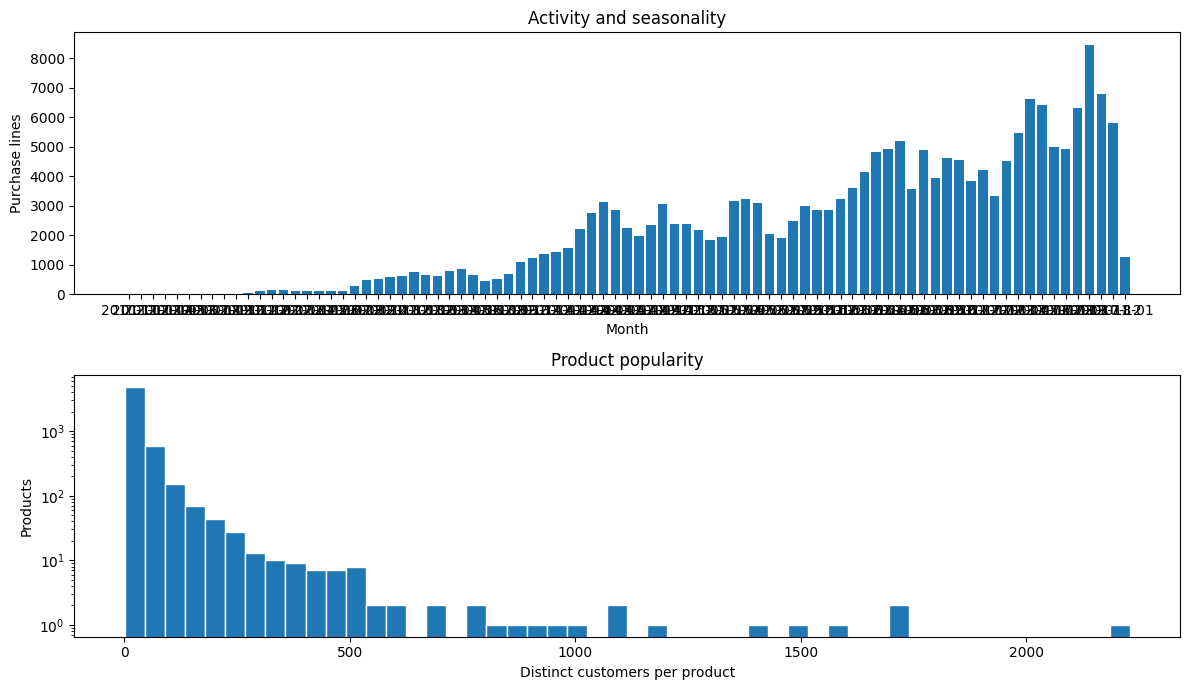

In [28]:
retail_pl = pl.DataFrame({name: events[name].to_numpy() for name in events.columns})
display(pl.DataFrame([cleaning_audit["raw_audit"]]))
display(retail_pl.select("user_id", "item_id", "rating", "description", "timestamp").head(8)) #invoice_id, "quantity", "price", "country"
display(retail_pl.select(
    pl.len().alias("clean_purchase_lines"),
    pl.col("user_id").n_unique().alias("customers"),
    pl.col("item_id").n_unique().alias("products"),
))
monthly = retail_pl.group_by(pl.col("timestamp").dt.truncate("1mo").alias("month")).len().sort("month")
product_activity = retail_pl.group_by("item_id").agg(
    pl.col("user_id").n_unique().alias("customers"), pl.len().alias("purchase_lines")
)
pair_activity = retail_pl.group_by("user_id", "item_id").len()
repeat_summary = pair_activity.select(
    (pl.col("len") > 1).mean().alias("fraction_of_pairs_with_repeat_purchase"),
    ((pl.col("len") - 1).sum() / pl.col("len").sum()).alias("repeat_line_fraction"),
)
display(repeat_summary)

fig, axes = plt.subplots(2, figsize=(12, 7))
axes[0].bar([str(value)[:7] for value in monthly["month"].to_list()], monthly["len"].to_numpy())
axes[0].set(xlabel="Month", ylabel="Purchase lines", title="Activity and seasonality")
axes[1].hist(product_activity["customers"].to_numpy(), bins=50, edgecolor = "white")
axes[1].set(xlabel="Distinct customers per product", ylabel="Products", title="Product popularity", yscale="log")
plt.tight_layout()
plt.show()

In [5]:
from scipy.sparse import csr_matrix

In [6]:
import math

In [7]:
HISTORY_START = pd.Timestamp("2010-11-03")
TRAIN_END = pd.Timestamp("2017-01-08")
VALID_END = pd.Timestamp("2017-05-08")
TEST_END = pd.Timestamp("2018-01-08")
train_raw = events[(events.timestamp >= HISTORY_START) & (events.timestamp < TRAIN_END)].copy()
valid_raw = events[(events.timestamp >= TRAIN_END) & (events.timestamp < VALID_END)].copy()
test_raw = events[(events.timestamp >= VALID_END) & (events.timestamp < TEST_END)].copy()
assert train_raw.timestamp.max() < valid_raw.timestamp.min()
assert valid_raw.timestamp.max() < test_raw.timestamp.min()

product_counts = train_raw.groupby("item_id").user_id.nunique().rename("customers").reset_index()
product_counts = product_counts.sort_values(["customers", "item_id"], ascending=[False, True])
if MAX_ITEMS is not None:
  product_counts = product_counts.head(MAX_ITEMS)
retained_products = set(product_counts.item_id)
retained_train = train_raw[train_raw.item_id.isin(retained_products)]
customer_counts = retained_train.groupby("user_id").item_id.nunique()
retained_users = customer_counts[customer_counts >= MIN_HISTORY_PRODUCTS].index[:60000]
print(("retained_users shape", retained_users.shape))
retained_train = retained_train[retained_train.user_id.isin(retained_users)].copy()
users = retained_train
products = retained_train.groupby("item_id").agg(
    title=("description", "last")
).reset_index()
users = users.sort_values("user_id").reset_index(drop=True)
products = products.sort_values("item_id").reset_index(drop=True)
user_ids, item_ids = users.user_id.to_numpy(), products.item_id.to_numpy()
user_to_idx = {int(value): index for index, value in enumerate(user_ids)}
item_to_idx = {str(value): index for index, value in enumerate(item_ids)}
n_users, n_items = len(users), len(products)

def map_events(frame):
  frame = frame.copy()
  frame["user_idx"] = frame.user_id.map(user_to_idx)
  frame["item_idx"] = frame.item_id.map(item_to_idx)
  return frame
train = map_events(retained_train)
train[["user_idx", "item_idx"]] = train[["user_idx", "item_idx"]].astype(np.int64)
valid, test = map_events(valid_raw), map_events(test_raw)
split_report = pd.DataFrame([
    {"split": name, "raw_purchase_lines": len(raw), "mapped_lines": int(mapped.user_idx.notna().mul(mapped.item_idx.notna()).sum()),
     "raw_customers": raw.user_id.nunique(), "raw_products": raw.item_id.nunique()}
    for name, raw, mapped in [("train", train_raw, train), ("validation", valid_raw, valid), ("test", test_raw, test)]
])
display(split_report)
print(f"Training-selected catalog: {n_users:,} customers, {n_items:,} products")
print("Retained training-line share:", round(len(train) / len(train_raw), 3))

def interaction_matrix(frame, positive_only=True):

  matrix = sparse.csr_matrix(
      (np.ones(len(frame)), (frame.user_idx.to_numpy(dtype=int), frame.item_idx.to_numpy(dtype=int))),
      shape=(n_users, n_items), dtype=np.float64
  )
  matrix.sum_duplicates()
  matrix.data[:] = 1.0
  return matrix
def rating_matrix(frame, positive_only=True):
  matrix = sparse.csr_matrix(
      (frame["rating"], (frame.user_idx.to_numpy(dtype=int), frame.item_idx.to_numpy(dtype=int))),
      shape=(n_users, n_items), dtype=np.float64
  )
  return matrix
X_train = interaction_matrix(train)
R_train = rating_matrix(train)
print("Binary training matrix:", X_train.shape, "distinct pairs:", X_train.nnz, "sparsity:", X_train.nnz/(X_train.shape[0] * X_train.shape[1]))
one_dense_mib = n_items ** 2 * np.dtype(np.float64).itemsize / 2 ** 20
print(f"One dense float64 item matrix: {one_dense_mib:.1f} MiB")
print(f"EASE solve working matrices: roughly {5 * one_dense_mib:.1f} MiB, "
      "plus histories, scores, cached data and other models; not measured peak RAM")

('retained_users shape', (60000,))


,split,raw_purchase_lines,mapped_lines,raw_customers,raw_products
0,train,124410,97190,76811,3133
1,validation,17943,4469,11633,3406
2,test,49917,5292,28565,5606


Training-selected catalog: 97,190 customers, 3,089 products
Retained training-line share: 0.781
Binary training matrix: (97190, 3089) distinct pairs: 97132 sparsity: 0.00032353617053579157
One dense float64 item matrix: 72.8 MiB
EASE solve working matrices: roughly 364.0 MiB, plus histories, scores, cached data and other models; not measured peak RAM


In [8]:
import time

In [9]:
train_cl = train.drop_duplicates(subset=["user_id", "item_id"])
time_array = np.array(train_cl['timestamp'])
t_s = np.min(time_array)
time_array = np.array([int((x - t_s)/86400000000000) for x in time_array])
t_m = int((np.max(np.array(test_raw['timestamp'])) - t_s)/86400000000000)
n_bns = math.ceil(t_m / 30)

In [10]:
metrics = []

In [11]:
hyperparameters = []

Centered vectors of user ratings:
$x_{ui} = r_{ui} - \overline {r_{u}}$
Similarity between items is counted:


$s(a, b) = \frac{x_{a} \cdot x_{b}}{||x_{a}|| ||x_{b}||} \cdot
\frac{n_{ab}}{n_{ab} + \lambda}.$

Ratings are counted:
$\hat{r}_{ui} = \overline {r_{u}} + \frac{\sum_{j}s(i,j)(r_{uj} - \overline r_{u})}{\sum_{j}|s(i, j)|}$

In [12]:
fit_model_1 = ItemSim().fit(R_train, X_train)
test_metrics, _ = evaluate_test(fit_model_1, train, test)
display(pd.Series(test_metrics, name="test").to_frame().round(4))

Evaluate ItemSim:   0%|          | 0/3350 [00:00<?, ?customer/s]

,test
Recall@10,0.0057
Precision@10,0.0009
NDCG@10,0.0033
HR@10,0.0087
eval_users,3350.0000
heldout_positives,49915.0000
unmapped_pairs,44623.0000
repeated_pairs,0.0000
eligible_positives,5292.0000
candidate_items,3089.0000


In [13]:
test_metrics['NDCG@10'], test_metrics['HR@10']

(0.0032573650174731027, 0.008656716417910448)

In [14]:
metrics.append([0.0033, 0.0087])

In [15]:
hyperparameters.append("shrinkage=10")

Remove the L1 penalty and the sign constant,
while retaining the zero diagonal:

$\underset{diag(B)=0}{min}||X - XB||^{2}_{F} + \lambda||B||^{2}_{F}.$
For column j, the stationary condition is
$(G + \lambda I)b_{j} = G_{:j} - n_{j}e_{j}.$ Enforcing
$b_{jj} = 0$ gives

$P = (G + \lambda I)^{-1},  B_{ij} = -\frac{P_{ij}}{jj}
(i \neq j), B_{jj} = 0$

The division is **column-wise**.

In [ ]:
EASE_GRID = [{"reg": 10.0}, {"reg": 100.0}, {"reg": 500.0}]
search_rows, selected_settings = [], {}
for name, model_class, grid in [("EASE", EASE, EASE_GRID)]:
  model_rows = []
  for setting in tqdm(grid, desc=f"{name} validation grid", unit="config"):
    model = timed_fit(model_class(**setting), R_train)
    metrics, _ = evaluate(model, train, valid)
    row = {"model": name, "setting": str(setting), "fit_seconds": model.fit_seconds_,
           "solver_warnings": getattr(model, "convergence_warnings_", 0), **metrics}
    search_rows.append(row)
    model_rows.append(row)
  best_index = int(np.argmax([row[f"NDCG@{K}"] for row in model_rows]))
  selected_settings[name] = grid[best_index]
linear_search = pd.DataFrame(search_rows)
display(linear_search[["model", "setting", f"Recall@{K}", f"NDCG@{K}",
                       "fit_seconds", "solver_warnings"]].round(4))
print("Selected on validation:", selected_settings)
assert linear_search.solver_warnings.sum() == 0

EASE validation grid:   0%|          | 0/3 [00:00<?, ?config/s]

EASE stages:   0%|          | 0/3 [00:00<?, ?stage/s]

Evaluate EASE:   0%|          | 0/2702 [00:00<?, ?customer/s]

EASE stages:   0%|          | 0/3 [00:00<?, ?stage/s]

Evaluate EASE:   0%|          | 0/2702 [00:00<?, ?customer/s]

EASE stages:   0%|          | 0/3 [00:00<?, ?stage/s]

Evaluate EASE:   0%|          | 0/2702 [00:00<?, ?customer/s]

,model,setting,Recall@10,NDCG@10,fit_seconds,solver_warnings
0,EASE,{'reg': 10.0},0.0143,0.0073,2.6797,0
1,EASE,{'reg': 100.0},0.0141,0.0073,7.0614,0
2,EASE,{'reg': 500.0},0.0139,0.0073,4.6010,0


Selected on validation: {'EASE': {'reg': 10.0}}


In [ ]:
fit_model_2 = EASE(reg=10).fit(R_train)
test_metrics, _ = evaluate_test(fit_model_2, train, test)
display(pd.Series(test_metrics, name="test").to_frame().round(4))

EASE stages:   0%|          | 0/3 [00:00<?, ?stage/s]

Evaluate EASE:   0%|          | 0/3350 [00:00<?, ?customer/s]

,test
Recall@10,0.0148
Precision@10,0.0019
NDCG@10,0.0074
HR@10,0.0191
eval_users,3350.0000
heldout_positives,49915.0000
unmapped_pairs,44623.0000
repeated_pairs,0.0000
eligible_positives,5292.0000
candidate_items,3089.0000


In [ ]:
test_metrics['NDCG@10'], test_metrics['HR@10']

(0.0074376736013320064, 0.0191044776119403)

In [16]:
metrics.append([0.0074, 0.0191])

In [17]:
hyperparameters.append("reg = 10")

In [ ]:
from contextlib import nullcontext

try:
  from threadpoolctl import threadpool_limits
except ImportError:
  def threadpool_limits(*args, **kwargs):
    return nullcontext()

Let $\Omega$ be the observed user-item pairs. With user factors $U \in \mathbb{R}^{m \times d}$ and item factors
$V \in \mathbb{R}^{n \times d}$, predict $\hat{r}_{ui} = U^{T}_{u}V_{i}$ and minimize

$L(U, V) = \sum_{u,i \in \Omega}(r_{ui} - U^{T}_{u}V_{i})^{2} + \lambda \sum_{u}||U_{u}|| + \lambda \sum_{i}||V_{i}||_{2}^{2}$

Holding $V$ fixed gives a ridge regression for user $u$. If $V_{u}$ contains factors for movies rated by that user, solve
$(V^{T}_{u}V_{u} + \lambda I)U_{u} = V^{T}_{u}r_{u}.$











In [ ]:
ALS_CONFIGS = [
    {"n_factors": 16, "reg": 5.0, "n_iters": 4},
    {"n_factors": 16, "reg": 5.0, "n_iters": 10},
    {"n_factors": 32, "reg": 5.0, "n_iters": 4},
    {"n_factors": 32, "reg": 5.0, "n_iters": 10},
    {"n_factors": 32, "reg": 10.0, "n_iters": 4},
    {"n_factors": 32, "reg": 30.0, "n_iters": 10},
    {"n_factors": 32, "reg": 100.0, "n_iters": 10},
]

In [ ]:
config_b = None
NDCG_m = 0
for config in ALS_CONFIGS:
  fit_model = ALSExplicit(**config, random_state=SEED).fit(R_train)
  validation, _ = evaluate_test(fit_model, train, valid)
  if validation["NDCG@10"] > NDCG_m:
    NDCG_m = validation["NDCG@10"]
    config_b = config

Evaluate ALSExplicit:   0%|          | 0/2702 [00:00<?, ?customer/s]

Evaluate ALSExplicit:   0%|          | 0/2702 [00:00<?, ?customer/s]

Evaluate ALSExplicit:   0%|          | 0/2702 [00:00<?, ?customer/s]

Evaluate ALSExplicit:   0%|          | 0/2702 [00:00<?, ?customer/s]

Evaluate ALSExplicit:   0%|          | 0/2702 [00:00<?, ?customer/s]

Evaluate ALSExplicit:   0%|          | 0/2702 [00:00<?, ?customer/s]

Evaluate ALSExplicit:   0%|          | 0/2702 [00:00<?, ?customer/s]

In [ ]:
config_b

{'n_factors': 32, 'reg': 100.0, 'n_iters': 10}

In [ ]:
fit_model_3 = ALSExplicit(**config_b).fit(R_train)
test_metrics, _ = evaluate_test(fit_model_3, train, test)
display(pd.Series(test_metrics, name="test").to_frame().round(4))

Evaluate ALSExplicit:   0%|          | 0/3350 [00:00<?, ?customer/s]

,test
Recall@10,0.0135
Precision@10,0.0017
NDCG@10,0.0065
HR@10,0.0167
eval_users,3350.0000
heldout_positives,49915.0000
unmapped_pairs,44623.0000
repeated_pairs,0.0000
eligible_positives,5292.0000
candidate_items,3089.0000


In [ ]:
test_metrics['NDCG@10'], test_metrics['HR@10']

(0.006504436808514377, 0.01671641791044776)

In [18]:
metrics.append([0.0065, 0.0167])

In [19]:
hyperparameters.append("n_factors: 32, reg: 100.0, n_iters: 10")

Here **SVD-style** means factorization fitted to observed ratings, not truncated matrix SVD. Let $\Omega$ be set of observed user-item pairs, $\mu$ the mean rating, $b_{u}, b_{i}$ the biases, and $p_{u}, q_{i} \in \mathbb{R}^{d}$ the latent factors. Then

$\hat{r_{ui}} = \mu + b_{u} + b_{i} + p_{u}^{T}q_{i}$,

$L_{SVD} = \sum_{u,i \in \Omega}(r_{ui} - \hat{r_{ui}})^{2} + \lambda(\sum_{u}(b_{u}^{2} + ||p_{u}||_{2}^{2}) + \sum_{i}(b_{i}^{2} + ||q_{i}||_{2}^{2})).$

For one observed rating, let $e_{ui} = r_{ui} - \hat{r_{ui}}.$ An SGD step for the factors is
$p_{u} \leftarrow p_{u} + \nu(e_{ui}q_{i} - \lambda p_{u}),
q_{i} \leftarrow q_{i} + \nu(e_{ui}p_{u} - \lambda q_{i}).$
The implementation below averages each user's gradients across that user's ratings in one step; it updates movie factors for individual ratings.

In **SVD++**, $N(u)$ contains the movies in the user's training history. Their additional fators $y_{j}$ form

$h_{u} = p_{u} + |N(u)|^{-\frac{1}{2}}\sum_{j \in N(u)y_{j}},      \hat{r_{ui}} = \mu + b_{u} + b_{i} + q_{i}^{T}h_{u}.$



The objective sums squared errors over $\Omega$ and regularizes $b_{u}, b_{i}, p_{u}, q_{i}$ **and** $y_{j}$:

$L_{SVD++} = \sum_{(u,i) \in \Omega}(r_{ui} - \hat{r_{ui}})^{2} + \lambda (\sum_{u}(b_{u}^{2} + ||p_{u}||_{2}^{2}) + \sum_{i}(b_{i}^{2} + ||q_{i}||_{2}^{2} + ||y_{i}||_{2}^{2}))$

The error $e_{ui}$ contributes a term proportional to $e_{ui}q_{i}/\sqrt{|N(u)|}$ to the update of every $y_{j}, j \in N(u)$. The history term uses whether a movie was rated, not the rating value.
In **timeSVD++**, some trainable parameters are dependant of time, which is done either by having a separate parameter for each day in observed time or by capturing a bean corresponding to a date. Observed time is divided on consequent bins, corresponding bin is measured by a number between 1 and 30.
$b_{i}(t) = b_{i} + b_{i, Bin(t)}$

$b_{u}(t) = b_{u} + \alpha_{u} \cdot dev_{u}(t) + b_{u,t}$,
$dev_{u}(t) = sign(t-t_{u}) \cdot |t - t_{u}|^{\beta}$,
$p_{uk}(t) = p_{uk} + \alpha_{uk} \cdot dev_{u}(t) + p_{uk, t}$

$\hat{r_{ui}}(t) = \mu + b_{i}(t) + b_{u}(t) + q_{i}^{T}(p_{u}(t) + |R(u)|^{-\frac{1}{2}}\sum_{j \in R(u)}y_{j})$














In [ ]:
MF_EPOCHS = 8 if n_users > 1000 else 15
R_final = R_train #X_train
#timesvd = timeBiasedFactorization(n_epochs = MF_EPOCHS, lr_user=0.001, t_m = t_m,
#                            n_bns = n_bns, time_array = time_array, random_state=SEED).fit(R_final)
timesvdpp = timeBiasedFactorization(
    n_epochs=MF_EPOCHS, use_history=True, lr_user=0.001, t_m = t_m,
                            n_bns = n_bns, time_array = time_array, random_state=SEED
).fit(R_final)
print(f"Factorization epochs: {MF_EPOCHS}")
assert timesvdpp.history_[-1]["train_rmse"] < timesvdpp.history_[0]["train_rmse"]
print("Train RMSE, timeSVD++", round(timesvdpp.history_[-1]["train_rmse"], 4))

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Factorization epochs: 8
Train RMSE, timeSVD++ 1.1876


In [ ]:
MF_EPOCHS = 8

In [ ]:
fit_model_4 = timeBiasedFactorization(n_epochs=MF_EPOCHS, t_m = t_m,
                            n_bns = n_bns, time_array = time_array, use_history=True, lr_user=0.001, random_state=SEED).fit(R_train)
test_metrics, _ = evaluate_test(fit_model_4, train, test)
display(pd.Series(test_metrics, name="test").to_frame().round(4))

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Evaluate timeBiasedFactorization:   0%|          | 0/3350 [00:00<?, ?customer/s]

,test
Recall@10,0.0045
Precision@10,0.0008
NDCG@10,0.0025
HR@10,0.0078
eval_users,3350.0000
heldout_positives,49915.0000
unmapped_pairs,44623.0000
repeated_pairs,0.0000
eligible_positives,5292.0000
candidate_items,3089.0000


In [ ]:
test_metrics['NDCG@10'], test_metrics['HR@10']

(0.0025213996139338436, 0.007761194029850746)

In [20]:
metrics.append([0.0025, 0.0078])

In [21]:
hyperparameters.append("n_factors=32, n_epochs = 8, use_history=False, lr_user=0.001, lr_item=0.08, reg=0.02")

An order-two FM uses a feature vector $x \in \mathbb{R}^{d}:
s(x) = w_{0} + \sum_{a}w_{a}x_{a} + \sum_{a < b}\langle
v_{a}, v_{b}\rangle x_{a}x_{b}.$

With user/product one-hot IDs only, this is $w_{0} + b_{u} + b_{i} + \langle p_{u}, q_{i} \rangle$: biased matrix factorization. Add **TF-IDF product-description
tokens** and **product price buckets** to share interactions between attributes. All descriptions come from training history.

FM includes within-side and cross-feature interactions; it is not identical to LightFM's feature-embedding model. The identity

$\sum_{a<b}\langle v_{a}, v_{b} \rangle x_{a}x_{b} = \frac{1}{2}\sum_{f} [(\sum_{a}v_{af}x_{a})^{2} - \sum_{a}v^{2}_{af}x^{2}_{a}]$

reduces computation to O($k$nnz(x)), with
gradient

$\frac{\partial s(x)}{\partial v_{af}} = x_{a}(\sum_{b}v_{bf}x_{b} - v_{af}x_{a}).$

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
text_encoder = TfidfVectorizer(lowercase=True, max_features=256, min_df=2, norm="l2")
description_features = text_encoder.fit_transform(products.title)
item_side = normalize_rows(sparse.hstack([description_features], format="csr"))

features_ids = FeatureMap(use_side_features=False, item_side=item_side, n_users=n_users, n_items=n_items)
features_side = FeatureMap(use_side_features=True, item_side=item_side, n_users=n_users, n_items=n_items)
print("ID-only features:", features_ids.n_features)
print("ID + metadata features:", features_side.n_features)
print("Side blocks are L2-normalized per row; identity features retain weight one")

ID-only features: 100279
ID + metadata features: 100535
Side blocks are L2-normalized per row; identity features retain weight one


In [ ]:
FM_SAMPLES_PER_EPOCH = None
FM_CHECKPOINTS = [3, 6, 12, 20]

Training FM-BPR IDs for validation...


FM-BPR IDs epochs:   0%|          | 0/20 [00:00<?, ?epoch/s]

Minibatches: 0batch [00:00, ?batch/s]

Evaluate FactorizationMachine:   0%|          | 0/2702 [00:00<?, ?customer/s]

FM-BPR IDs selected epoch: 3 seconds: 353.66
Training FM-BPR + metadata for validation...


FM-BPR IDs + metadata epochs:   0%|          | 0/20 [00:00<?, ?epoch/s]

Minibatches: 0batch [00:00, ?batch/s]

Evaluate FactorizationMachine:   0%|          | 0/2702 [00:00<?, ?customer/s]

FM-BPR + metadata selected epoch: 3 seconds: 370.15


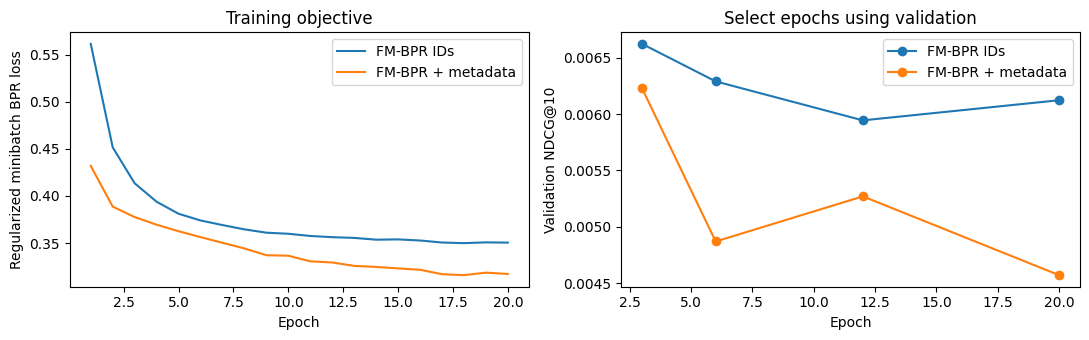

Training loss uses freshly samples megatives


In [ ]:
feature_b = None
val_b = 0
fm_validation, fm_epochs =  {}, {}
for name, features in [("FM-BPR IDs", features_ids), ("FM-BPR + metadata", features_side)]:
  print("Training", name, "for validation...", flush=True)
  model = timed_fit(FactorizationMachine(epochs=max(FM_CHECKPOINTS), random_state=SEED),
                    train, features, validation=valid, checkpoints=FM_CHECKPOINTS)
  baseline_validation, _ = evaluate_test(model, train, valid)
  if baseline_validation['NDCG@10'] > val_b:
    val_b = baseline_validation['NDCG@10']
    feature_b = features
  fm_validation[name] = model
  fm_epochs[name] = model.best_epoch_
  print(name, "selected epoch:", model.best_epoch_, "seconds:", round(model.fit_seconds_, 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, model in fm_validation.items():
  history = pd.DataFrame(model.history_)
  axes[0].plot(history.epoch, history.training_bpr, label=name)
  checkpoints = history.dropna(subset=[f"validation_NDCG@{K}"])
  axes[1].plot(checkpoints.epoch, checkpoints[f"validation_NDCG@{K}"], marker="o", label=name)
axes[0].set(xlabel="Epoch", ylabel="Regularized minibatch BPR loss", title="Training objective")
axes[1].set(xlabel="Epoch", ylabel=f"Validation NDCG@{K}", title="Select epochs using validation")
for ax in axes:
  ax.legend()
plt.tight_layout()
plt.show()
print("Training loss uses freshly samples megatives")

In [ ]:
fit_model_5 = timed_fit(FactorizationMachine(epochs=max(FM_CHECKPOINTS), random_state=SEED),
                    train, feature_b, checkpoints=FM_CHECKPOINTS)
test_metrics, _ = evaluate_test(fit_model_5, train, test)
display(pd.Series(test_metrics, name="test").to_frame().round(4))

FM-BPR IDs epochs:   0%|          | 0/20 [00:00<?, ?epoch/s]

Minibatches: 0batch [00:00, ?batch/s]

Evaluate FactorizationMachine:   0%|          | 0/3350 [00:00<?, ?customer/s]

,test
Recall@10,0.0143
Precision@10,0.0019
NDCG@10,0.0067
HR@10,0.0188
eval_users,3350.0000
heldout_positives,49915.0000
unmapped_pairs,44623.0000
repeated_pairs,0.0000
eligible_positives,5292.0000
candidate_items,3089.0000


In [ ]:
test_metrics['NDCG@10'], test_metrics['HR@10']

(0.006667456699294157, 0.018805970149253733)

In [22]:
metrics.append([0.0067, 0.0188])

In [23]:
hyperparameters.append("n_factors=16, epochs=30, lr=0.01, reg=1e-5, batch_size=512")

Chosen metrics are NDCG@10 and HR@10. NDCG scales with regard to the quality of how items for users are recommended, making it resonable to use for comparing models. HR is intuitive for recommending purchasable items to users as it shows whether a user actually bought anything out of top k recommended items.

In [24]:
df_res = pd.DataFrame(index=['NDCG@10', 'HR@10', 'Hyperparameters'])
model_n = ["Item-to-Item", "EASE", "ALS", "timeSVD++", "FM"]
for i in range(len(model_n)):
  df_res[model_n[i]] =  metrics[i] + [hyperparameters[i]]

In [25]:
df_res

,Item-to-Item,EASE,ALS,timeSVD++,FM
NDCG@10,0.0033,0.0074,0.0065,0.0025,0.0067
HR@10,0.0087,0.0191,0.0167,0.0078,0.0188
Hyperparameters,shrinkage=10,reg = 10,"n_factors: 32, reg: 100.0, n_iters: 10","n_factors=32, n_epochs = 8, use_history=False,...","n_factors=16, epochs=30, lr=0.01, reg=1e-5, ba..."


**Conclusion**

Best results were shown by EASE, which may be due to the sparsity of used interaction matrix and that in this particular case using latent representations may have lead to overlook of some information rather than capturing non-explicit features.
Experiment limits the number of users in training set, as not keeping such limitation may result in RAM overflow. Using metadata while training can result in easier loss optimization as we can see in experiments corresponding to MF.